# 🛡️ NIDS/Botnet Detection Pipeline - Stratified K-Fold Cross-Validation (Chống Data Leakage)

Tài liệu này tái cấu trúc toàn diện pipeline huấn luyện phát hiện xâm nhập mạng (NIDS / Botnet) trên tập dữ liệu luồng mạng CTU-13 (`ctu13_merged.csv`) theo chuẩn học thuật tại `.agents/workflows/skill.md`:

### 🎯 Các nguyên tắc cốt lõi đã áp dụng:
1. **Chia Fold trước, Fit xử lý sau**: Tuyệt đối không tính toán thống kê (Median, Standard Deviation), không chạy Feature Selection (`ExtraTreesClassifier`), và không fit `StandardScaler` trên toàn bộ tập dữ liệu trước vòng lặp K-Fold.
2. **Khép kín trong từng Fold**: Mọi thao tác `fit` chỉ được thực hiện trên `X_train` của fold hiện tại. `X_val` và `X_test` chỉ được dùng phương thức `transform`.
3. **Cô lập trạng thái mô hình**: Mỗi fold khởi tạo đối tượng mô hình mới (reset weights hoàn toàn), `optimizer`, `scheduler`, và `GradScaler` mới để triệt tiêu rò rỉ trọng số giữa các fold.
4. **Tách 3 tập cục bộ trong Fold**: Mỗi fold chia thành `X_test` (dùng để đánh giá độc lập cuối fold) và `X_train_val` (cắt tiếp 10% làm `X_val` phục vụ Early Stopping và lưu best checkpoint, 90% còn lại dùng huấn luyện).
5. **Đánh giá đa chiều & Tổng hợp**: Báo cáo Accuracy, Precision, Recall, Macro F1 cho từng fold, tính Mean ± Std và vẽ Confusion Matrix tổng hợp.


In [1]:
import os, math, warnings, gc, random, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything(SEED)

# Tự động phát hiện GPU
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f" Thiết bị huấn luyện (Device): {DEVICE}")

 Thiết bị huấn luyện (Device): cuda


In [2]:
# =========================================================================
# ⚙️ CẤU HÌNH PIPELINE & HYPERPARAMETERS
# =========================================================================
# Đường dẫn dữ liệu CTU-13 đã gộp
DATA_PATH   = r"C:\Users\ADMIN\Paper_1\git_data\Cross-valadation\ctu13_merged.csv"
CLASS_NAMES = ['Benign', 'Botnet']
N_APT_PHASES = 2

# Cấu hình K-Fold & Feature Selection
K_FOLDS     = 5
N_SELECT    = 20
VAL_RATIO   = 0.10     # 10% tập train_val dùng làm validation set nội bộ mỗi fold

# Chế độ chạy thử nghiệm (DEBUG_SUBSET)
# - Đặt DEBUG_SUBSET = True: Đọc mẫu đại diện (đảm bảo đủ 2 class) để test nhanh pipeline
# - Đặt DEBUG_SUBSET = False: Đọc 100% dữ liệu thực tế (15 triệu dòng) để huấn luyện chính thức
DEBUG_SUBSET         = False
DEBUG_SAMPLES_BENIGN = 90000
DEBUG_SAMPLES_BOTNET = 10000

# Training Hyperparameters
BATCH_SIZE    = 1024
NUM_WORKERS   = 0
EPOCHS        = 5
LR            = 3e-4
WARMUP_EPOCHS = 2

# Tiền xử lý Outliers
OUTLIER_TH    = 3.0
PRE_BATCH     = 50000

# Kiến trúc mô hình Titan
D_MODEL       = 128
N_HEADS       = 8
N_PERSIST     = 4
LMM_HIDDEN    = 128
SWA_WINDOW    = 16
LMM_LAYERS    = 4
HEAD_DROPOUT  = 0.2
LMM_DROPOUT   = 0.15
TPA_R_Q       = 2
TPA_R_K       = 2
TPA_R_V       = 2

# Loss Function (Class-Balanced Focal Loss)
FOCAL_BETA    = 0.9999
FOCAL_GAMMA   = 1.5

print(f"Pipeline Configuration: K_FOLDS={K_FOLDS}, N_SELECT={N_SELECT}")
print(f"DEBUG_SUBSET: {DEBUG_SUBSET} (EPOCHS={EPOCHS}, BATCH_SIZE={BATCH_SIZE})")

Pipeline Configuration: K_FOLDS=5, N_SELECT=20
DEBUG_SUBSET: False (EPOCHS=5, BATCH_SIZE=1024)


In [3]:
# =========================================================================
# 📥 ĐỌC VÀ LÀM SẠCH DỮ LIỆU THÔ (TUYỆT ĐỐI CHƯA TÍNH THỐNG KÊ FIT / TRANSFORM)
# =========================================================================
print(f"Đang nạp dữ liệu từ: {DATA_PATH}...")

if DEBUG_SUBSET:
    print(f"⚠️ Chế độ DEBUG_SUBSET đang BẬT: Đọc mẫu đại diện ({DEBUG_SAMPLES_BENIGN:,} Benign + {DEBUG_SAMPLES_BOTNET:,} Botnet)...")
    chunks = []
    collected_0 = 0
    collected_1 = 0
    chunksize = 100000
    
    for chunk in pd.read_csv(DATA_PATH, chunksize=chunksize, low_memory=False):
        c0 = chunk[chunk['is_botnet'] == 0]
        c1 = chunk[chunk['is_botnet'] == 1]
        
        need_0 = DEBUG_SAMPLES_BENIGN - collected_0
        need_1 = DEBUG_SAMPLES_BOTNET - collected_1
        
        if need_0 > 0 and len(c0) > 0:
            take_0 = c0.iloc[:need_0]
            chunks.append(take_0)
            collected_0 += len(take_0)
            
        if need_1 > 0 and len(c1) > 0:
            take_1 = c1.iloc[:need_1]
            chunks.append(take_1)
            collected_1 += len(take_1)
            
        if collected_0 >= DEBUG_SAMPLES_BENIGN and collected_1 >= DEBUG_SAMPLES_BOTNET:
            break
            
    df = pd.concat(chunks, ignore_index=True)
    del chunks
    gc.collect()
else:
    print("Đang đọc toàn bộ dữ liệu (15M+ dòng, vui lòng chờ)...")
    df = pd.read_csv(DATA_PATH, low_memory=False)

# Loại bỏ các dòng trùng lặp
df = df.drop_duplicates().reset_index(drop=True)
print(f"Tổng số mẫu sau khi loại trùng lặp: {len(df):,}")

# Chuẩn hóa nhãn nhị phân y
if 'is_botnet' in df.columns:
    y = df['is_botnet'].astype(np.int64).values
elif 'Label' in df.columns:
    y = df['Label'].astype(str).str.contains('Botnet|Attack', case=False).astype(np.int64).values
else:
    raise ValueError("Không tìm thấy cột nhãn (is_botnet hoặc Label)!")

# 1. Loại bỏ các cột định danh mạng và thời gian theo chuẩn NIDS
id_time_cols = ['StartTime', 'LastTime', 'SrcAddr', 'DstAddr', 'sTos', 'dTos', 'Label', 'is_botnet', 'FTP_COMMAND_RET_CODE']
df = df.drop(columns=[c for c in id_time_cols if c in df.columns], errors='ignore')

# 2. Xử lý cổng mạng (Sport, Dport) sang số
for port_col in ['Sport', 'Dport']:
    if port_col in df.columns:
        df[port_col] = pd.to_numeric(df[port_col], errors='coerce').fillna(0)

# 3. Mã hóa các cột chuỗi dạng phân loại (Proto, State, Dir) bằng LabelEncoder
categorical_cols = [c for c in ['Proto', 'State', 'Dir'] if c in df.columns and not pd.api.types.is_numeric_dtype(df[c].dtype)]
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str).fillna('Unknown'))

# 4. Chuyển đổi toàn bộ các cột còn lại sang số và fillna(0)
for col in df.columns:
    if not pd.api.types.is_numeric_dtype(df[col].dtype):
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

df = df.fillna(0)

# 5. Loại bỏ các cột hằng số (std == 0)
std_series = df.std(numeric_only=True)
const_cols = std_series[std_series == 0].index.tolist()
if const_cols:
    print(f"Loại bỏ các cột hằng số: {const_cols}")
    df = df.drop(columns=const_cols)

X = df.copy()
del df
gc.collect()

print(f"\n✅ Hoàn tất làm sạch thô: X.shape = {X.shape}, y.shape = {y.shape}")
print("Phân phối nhãn:")
for i, name in enumerate(CLASS_NAMES):
    cnt = int((y == i).sum())
    pct = cnt / len(y) * 100
    print(f"   {i} - {name:15s}: {cnt:,} ({pct:.2f}%)")

Đang nạp dữ liệu từ: C:\Users\ADMIN\Paper_1\git_data\Cross-valadation\ctu13_merged.csv...
Đang đọc toàn bộ dữ liệu (15M+ dòng, vui lòng chờ)...
Tổng số mẫu sau khi loại trùng lặp: 15,266,062

✅ Hoàn tất làm sạch thô: X.shape = (15266062, 26), y.shape = (15266062,)
Phân phối nhãn:
   0 - Benign         : 14,848,185 (97.26%)
   1 - Botnet         : 417,877 (2.74%)


In [4]:
# =========================================================================
# 🧠 KIẾN TRÚC MÔ HÌNH TITAN & CÁC MODULE PYTORCH
# =========================================================================
ROPE_BASE = 1000.0   

def build_rope_cache(seq_len, inv_freq, device):
    t = torch.arange(seq_len, device=device).float()
    angles = torch.outer(t, inv_freq.to(device))          
    cos = angles.cos().repeat_interleave(2, dim=-1)
    sin = angles.sin().repeat_interleave(2, dim=-1)
    return cos, sin

def apply_rope(x, cos, sin):
    cos = cos.unsqueeze(0).unsqueeze(2)   
    sin = sin.unsqueeze(0).unsqueeze(2)   
    x1 = x[..., 0::2]; x2 = x[..., 1::2]
    x_rot = torch.stack((-x2, x1), dim=-1).flatten(-2)
    return x * cos + x_rot * sin

class Adaptive_Weighting_Attention(nn.Module):
    def __init__(self, d_model, n_heads, d_head, R):
        super().__init__()
        assert R >= 1 and n_heads >= 1 and d_head >= 1
        self.R, self.h, self.dh = R, n_heads, d_head
        self.A = nn.Linear(d_model, R * n_heads, bias=False)
        self.B = nn.Linear(d_model, R * d_head,  bias=False)
        nn.init.xavier_uniform_(self.A.weight)
        nn.init.xavier_uniform_(self.B.weight)
        self.alpha = nn.Parameter(torch.ones(R, n_heads))

    def forward(self, x):                       
        B, L, _ = x.shape
        a = self.A(x).view(B, L, self.R, self.h)    
        b = self.B(x).view(B, L, self.R, self.dh)   
        a = a * self.alpha.view(1, 1, self.R, self.h)
        out = torch.einsum('blrh,blrd->blhd', a, b) / float(self.R)
        return out                              

class FeatureEmbedding(nn.Module):
    """Continuous value embedding: mỗi feature i -> x_i * w_i + b_i (+ MLP nhỏ)."""
    def __init__(self, n_features, d):
        super().__init__()
        self.w    = nn.Parameter(torch.randn(n_features, d) * 0.02)
        self.b    = nn.Parameter(torch.zeros(n_features, d))
        self.proj = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, d))
        self.pos  = nn.Embedding(n_features, d)
        self.norm = nn.LayerNorm(d)

    def forward(self, x):
        B, L = x.shape
        h = x.unsqueeze(-1) * self.w.unsqueeze(0) + self.b.unsqueeze(0)
        h = h + self.proj(h)
        p = torch.arange(L, device=x.device).unsqueeze(0).expand(B, L)
        return self.norm(h + self.pos(p))

class NeuralLongTermMemory(nn.Module):
    def __init__(self, d, n_heads=8, lmm_r_q=2, lmm_r_k=2, lmm_r_v=2,
                 num_blocks=4, dropout=0.15):
        super().__init__()
        assert d % n_heads == 0
        self.h  = n_heads
        self.dh = d // n_heads

        self.tpa_q = Adaptive_Weighting_Attention(d, n_heads, self.dh, lmm_r_q)
        self.tpa_k = Adaptive_Weighting_Attention(d, n_heads, self.dh, lmm_r_k)
        self.tpa_v = Adaptive_Weighting_Attention(d, n_heads, self.dh, lmm_r_v)

        half = self.dh // 2
        inv_freq = 1.0 / (ROPE_BASE ** (torch.arange(0, half * 2, 2).float() / (half * 2)))
        self.register_buffer('inv_freq', inv_freq)

        hidden = d * 4 // 3
        self.M_blocks = nn.ModuleList([
            nn.ModuleDict({
                'norm': nn.LayerNorm(d),
                'fc1':  nn.Linear(d, hidden),
                'act':  nn.GELU(),
                'drop': nn.Dropout(dropout),
                'fc2':  nn.Linear(hidden, d),
            }) for _ in range(num_blocks)
        ])
        self.M_norm = nn.LayerNorm(d)

        self.alpha = nn.Linear(d, 1)
        self.eta   = nn.Linear(d, 1)
        self.theta = nn.Linear(d, 1)

        self.out_proj = nn.Linear(d, d)
        self.norm     = nn.LayerNorm(d)

    def _M(self, x):
        for b in self.M_blocks:
            h = b['norm'](x)
            h = b['fc2'](b['drop'](b['act'](b['fc1'](h))))
            x = x + h
        return self.M_norm(x)

    def forward(self, h):
        B, L, D = h.shape

        q = self.tpa_q(h)
        k = self.tpa_k(h)
        v = self.tpa_v(h)

        cos, sin = build_rope_cache(L, self.inv_freq, h.device)
        q = apply_rope(q, cos, sin)
        k = apply_rope(k, cos, sin)

        q_flat = q.reshape(B, L, D)
        k_flat = k.reshape(B, L, D)
        v_flat = v.reshape(B, L, D)

        a = torch.sigmoid(self.alpha(h))
        e = torch.sigmoid(self.eta(h))
        t = torch.sigmoid(self.theta(h)) * 0.1

        k_M = self._M(k_flat.reshape(B * L, D)).reshape(B, L, D)
        q_M = self._M(q_flat.reshape(B * L, D)).reshape(B, L, D)

        Mt = torch.zeros(B, D, device=h.device, dtype=h.dtype)
        St = torch.zeros(B, D, device=h.device, dtype=h.dtype)
        outs = []

        for i in range(L):
            v_hat = k_M[:, i] + Mt
            St = e[:, i] * St - t[:, i] * 2.0 * (v_hat - v_flat[:, i])
            Mt = (1.0 - a[:, i]) * Mt + St
            outs.append(self.out_proj(q_M[:, i] + Mt))

        return self.norm(torch.stack(outs, dim=1))

class SlidingWindowAttention(nn.Module):
    def __init__(self, d, n_heads, window=16,
                 swa_r_q=2, swa_r_k=2, swa_r_v=2):
        super().__init__()
        assert d % n_heads == 0
        self.h      = n_heads
        self.dh     = d // n_heads
        self.window = window
        self.scale  = self.dh ** -0.5

        self.tpa_q = Adaptive_Weighting_Attention(d, n_heads, self.dh, swa_r_q)
        self.tpa_k = Adaptive_Weighting_Attention(d, n_heads, self.dh, swa_r_k)
        self.tpa_v = Adaptive_Weighting_Attention(d, n_heads, self.dh, swa_r_v)

        half = self.dh // 2
        inv_freq = 1.0 / (ROPE_BASE ** (torch.arange(0, half * 2, 2).float() / (half * 2)))
        self.register_buffer('inv_freq', inv_freq)

        self.out_proj = nn.Linear(d, d)
        self.norm     = nn.LayerNorm(d)   

    def forward(self, x):                 
        B, L, D = x.shape
        h = self.norm(x)

        q = self.tpa_q(h)
        k = self.tpa_k(h)
        v = self.tpa_v(h)

        cos, sin = build_rope_cache(L, self.inv_freq, x.device)
        q = apply_rope(q, cos, sin)
        k = apply_rope(k, cos, sin)

        q = q.permute(0, 2, 1, 3)
        k = k.permute(0, 2, 1, 3)
        v = v.permute(0, 2, 1, 3)

        idx  = torch.arange(L, device=x.device)
        diff = idx.unsqueeze(0) - idx.unsqueeze(1)
        mask = (diff > 0) | (diff < -(self.window - 1))
        mask = mask.unsqueeze(0).unsqueeze(0)

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.masked_fill(mask, float('-inf'))
        attn = F.softmax(attn, dim=-1)

        out = attn @ v                                   
        out = out.permute(0, 2, 1, 3).reshape(B, L, D)  
        return x + self.out_proj(out)

class Titan(nn.Module):
    def __init__(self, n_features, n_classes,
                 d=128, n_heads=8, n_persist=4, swa_window=16,
                 lmm_blocks=4, lmm_dropout=0.15, head_dropout=0.2,
                 r_q=2, r_k=2, r_v=2):
        super().__init__()
        self.embed  = FeatureEmbedding(n_features, d)
        self.P      = nn.Parameter(torch.randn(1, n_persist, d) * 0.02)

        self.swa = SlidingWindowAttention(d, n_heads, swa_window,
                                          swa_r_q=r_q, swa_r_k=r_k, swa_r_v=r_v)
        self.lmm = NeuralLongTermMemory(d, n_heads,
                                         lmm_r_q=r_q, lmm_r_k=r_k, lmm_r_v=r_v,
                                         num_blocks=lmm_blocks, dropout=lmm_dropout)

        self.merge     = nn.Linear(d * 2, d)
        self.gate      = nn.Linear(d, d)
        self.gate_norm = nn.LayerNorm(d)

        self.head = nn.Sequential(
            nn.LayerNorm(d),
            nn.Linear(d, d * 2),
            nn.GELU(),
            nn.Dropout(head_dropout),
            nn.Linear(d * 2, d * 2),
            nn.GELU(),
            nn.Dropout(head_dropout),
            nn.Linear(d * 2, d),
            nn.GELU(),
            nn.Dropout(head_dropout / 2),
            nn.Linear(d, n_classes)
        )
        self.np = n_persist

    def forward(self, x):
        B  = x.size(0)
        h  = self.embed(x)
        xt = torch.cat([self.P.expand(B, -1, -1), h], dim=1)

        y_swa = self.swa(xt)
        y_lmm = self.lmm(xt)

        out = self.merge(torch.cat([y_swa, y_lmm], dim=-1))
        out = self.gate_norm(out * torch.sigmoid(self.gate(xt)))
        out = out[:, self.np:].mean(dim=1)
        return self.head(out)

class ClassBalancedFocalLoss(nn.Module):
    """Class-Balanced Focal Loss xử lý mất cân bằng lớp trầm trọng trong NIDS."""
    def __init__(self, samples_per_class, beta=0.9999, gamma=1.5):
        super().__init__()
        samples_per_class = np.asarray(samples_per_class, dtype=np.float64)
        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.mean()
        self.register_buffer('weights', torch.tensor(weights, dtype=torch.float32))
        self.gamma = gamma

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        p_t = torch.exp(-ce_loss)
        focal_term = (1.0 - p_t).pow(self.gamma)
        loss = focal_term * ce_loss * self.weights[targets]
        return loss.mean()

class TokenDS(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

In [5]:
# =========================================================================
# 🔄 CÁC HÀM TIỀN XỬ LÝ KHÉP KÍN TRONG FOLD & HUẤN LUYỆN / ĐÁNH GIÁ
# =========================================================================

def robust_preprocess_fold(X_train, X_val, X_test, batch_size=PRE_BATCH, outlier_threshold=OUTLIER_TH):
    """Fit medians & stds CHỈ TRÊN X_train, transform trên X_train, X_val, X_test."""
    X_train = np.asarray(X_train).astype(np.float32)
    X_val   = np.asarray(X_val).astype(np.float32)
    X_test  = np.asarray(X_test).astype(np.float32)

    # 1. Tính statistics trên mẫu đại diện CHỈ TỪ X_train của fold hiện tại
    sample_size = min(100000, len(X_train))
    sample_indices = np.random.choice(len(X_train), sample_size, replace=False)
    X_sample = X_train[sample_indices].copy()
    X_sample[np.isinf(X_sample)] = np.nan

    medians = np.nan_to_num(np.nanmedian(X_sample, axis=0), nan=0.0).astype(np.float32)
    stds    = np.nan_to_num(np.nanstd(X_sample, axis=0),    nan=1.0).astype(np.float32)
    stds[stds == 0] = 1.0
    del X_sample

    # 2. Transform NaN/Inf/Outlier theo batch bằng medians & stds của train
    def process_batch(batch):
        batch = batch.copy()
        batch[np.isinf(batch)] = np.nan
        z = np.abs((batch - medians) / stds)
        outlier_mask = z > outlier_threshold
        nan_mask = np.isnan(batch)
        fill = np.broadcast_to(medians, batch.shape)
        batch[outlier_mask | nan_mask] = fill[outlier_mask | nan_mask]
        return np.clip(batch, -1e6, 1e6)

    def process_all(A):
        out = []
        for s in range(0, len(A), batch_size):
            out.append(process_batch(A[s:s + batch_size]))
        return np.vstack(out)

    X_train_p = process_all(X_train)
    X_val_p   = process_all(X_val)
    X_test_p  = process_all(X_test)

    return X_train_p, X_val_p, X_test_p

def feature_selection_fold(X_tr_proc, y_tr, X_val_proc, X_te_proc, feature_names, n_select=N_SELECT):
    """Fit ExtraTreesClassifier CHỈ TRÊN X_train của fold, transform trên cả 3 tập."""
    selector = SelectFromModel(
        ExtraTreesClassifier(n_estimators=50, random_state=SEED, n_jobs=-1, verbose=0),
        max_features=n_select,
        threshold=-np.inf
    )
    selector.fit(X_tr_proc, y_tr)

    X_tr_sel  = selector.transform(X_tr_proc)
    X_val_sel = selector.transform(X_val_proc)
    X_te_sel  = selector.transform(X_te_proc)

    selected_mask = selector.get_support()
    importances = selector.estimator_.feature_importances_
    selected_features = [feature_names[i] for i in np.argsort(importances)[::-1] if selected_mask[i]]

    return X_tr_sel, X_val_sel, X_te_sel, selected_features

def scale_fold(X_tr_sel, X_val_sel, X_te_sel):
    """Fit StandardScaler CHỈ TRÊN X_train_selected của fold, transform trên val và test."""
    scaler = StandardScaler()
    tok_tr  = scaler.fit_transform(X_tr_sel).astype(np.float32)
    tok_val = scaler.transform(X_val_sel).astype(np.float32)
    tok_te  = scaler.transform(X_te_sel).astype(np.float32)
    return tok_tr, tok_val, tok_te

def train_epoch(model, dataloader, criterion, optimizer, scaler, device, amp_enabled):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in dataloader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda" if amp_enabled else "cpu", enabled=amp_enabled, dtype=torch.float16):
            logits = model(xb)
            loss = criterion(logits, yb)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()
        total += yb.size(0)
    return running_loss / total, correct / total

def validate_epoch(model, dataloader, criterion, device, max_samples=100000):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in dataloader:
            xb, yb = xb.to(device), yb.to(device)
            with torch.autocast(device_type="cuda" if device.type == "cuda" else "cpu", 
                                enabled=(device.type == "cuda"), dtype=torch.float16):
                logits = model(xb)
                loss = criterion(logits, yb)
            running_loss += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            correct += (preds == yb).sum().item()
            total += yb.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(yb.cpu().numpy())
            if max_samples and total >= max_samples:
                break
    return running_loss / total, correct / total, all_preds, all_labels

def evaluate_model(model, dataloader, device):
    model.eval()
    all_preds, all_labels = [], []
    amp_enabled = device.type == "cuda"
    with torch.no_grad():
        for xb, yb in dataloader:
            xb, yb = xb.to(device), yb.to(device)
            with torch.autocast(device_type="cuda" if amp_enabled else "cpu", enabled=amp_enabled, dtype=torch.float16):
                logits = model(xb)
            preds = logits.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(yb.cpu().numpy())
    return {'pred': np.array(all_preds), 'true': np.array(all_labels)}

def metrics_from_confusion(y_true, y_pred, n_classes, class_names):
    """Tính đầy đủ TP, TN, FP, FN, Accuracy, Precision, Recall, F1."""
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='macro', zero_division=0)

    cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))
    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)
    TN = cm.sum() - (FP + FN + TP)
    support = cm.sum(axis=1)

    class_acc  = (TP + TN) / (TP + TN + FP + FN)
    class_prec = np.divide(TP, TP + FP, out=np.zeros_like(TP, dtype=float), where=(TP + FP) != 0)
    class_rec  = np.divide(TP, TP + FN, out=np.zeros_like(TP, dtype=float), where=(TP + FN) != 0)
    class_f1   = np.divide(2 * class_prec * class_rec, class_prec + class_rec, 
                           out=np.zeros_like(class_prec, dtype=float), where=(class_prec + class_rec) != 0)

    df_metrics = pd.DataFrame({
        'TP': TP, 'TN': TN, 'FP': FP, 'FN': FN,
        'Accuracy': class_acc, 'Precision': class_prec,
        'Recall': class_rec, 'F1': class_f1, 'Support': support
    }, index=class_names)

    return {
        'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1,
        'cm': cm, 'per_class': df_metrics
    }

In [6]:
# =========================================================================
# 🚀 VÒNG LẶP STRATIFIED K-FOLD CROSS-VALIDATION (CHỐNG DATA LEAKAGE)
# =========================================================================
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)

fold_results = []
fold_cms = []
all_selected_features = []

print(f"\n{'='*75}")
print(f"BẮT ĐẦU HUẤN LUYỆN STRATIFIED {K_FOLDS}-FOLD CROSS-VALIDATION TRÊN {DEVICE}")
print(f"{'='*75}\n")

for fold, (train_val_idx, test_idx) in enumerate(skf.split(X, y)):
    print(f"\n{'#'*30} FOLD {fold + 1}/{K_FOLDS} {'#'*30}")
    
    # 1. Tách tập train_val và test độc lập của fold
    X_tr_val_raw = X.iloc[train_val_idx]
    y_tr_val     = y[train_val_idx]
    
    X_te_raw     = X.iloc[test_idx]
    y_te         = y[test_idx]
    
    # 2. Tách Validation Set nội bộ từ train_val (Stratified 90% Train / 10% Val)
    tr_sub_idx, val_sub_idx = train_test_split(
        np.arange(len(y_tr_val)),
        test_size=VAL_RATIO,
        stratify=y_tr_val,
        random_state=SEED + fold
    )
    
    X_tr_raw  = X_tr_val_raw.iloc[tr_sub_idx]
    y_tr      = y_tr_val[tr_sub_idx]
    
    X_val_raw = X_tr_val_raw.iloc[val_sub_idx]
    y_val     = y_tr_val[val_sub_idx]
    
    print(f"Fold {fold + 1} Dataset Split: Train={len(y_tr):,}, Val={len(y_val):,}, Test={len(y_te):,}")
    
    # 3. Tiền xử lý Robust Preprocessing (Fit trên Train, Transform trên Val/Test)
    print("  [1/3] Robust Outlier Preprocessing (Fit on Train, Transform on Val & Test)...")
    X_tr_proc, X_val_proc, X_te_proc = robust_preprocess_fold(X_tr_raw, X_val_raw, X_te_raw)
    
    # 4. Feature Selection với Extra-Trees (Fit trên Train, Transform trên Val/Test)
    print(f"  [2/3] Feature Selection (Extra-Trees, N_SELECT={N_SELECT}) fit on Train...")
    feature_names = X_tr_raw.columns.tolist()
    X_tr_sel, X_val_sel, X_te_sel, selected_feats = feature_selection_fold(
        X_tr_proc, y_tr, X_val_proc, X_te_proc, feature_names, N_SELECT
    )
    all_selected_features.append(selected_feats)
    print(f"  Top 5 Features được chọn: {selected_feats[:5]}")
    
    # 5. StandardScaler (Fit trên Train, Transform trên Val/Test)
    print("  [3/3] StandardScaler fit on Train, transform on Val & Test...")
    tok_tr, tok_val, tok_te = scale_fold(X_tr_sel, X_val_sel, X_te_sel)
    SEQ_LEN = tok_tr.shape[1]
    
    # 6. PyTorch DataLoaders
    kw = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
    train_loader = DataLoader(TokenDS(tok_tr,  y_tr),  batch_size=BATCH_SIZE, shuffle=True,  drop_last=True, **kw)
    val_loader   = DataLoader(TokenDS(tok_val, y_val), batch_size=BATCH_SIZE, shuffle=False, **kw)
    test_loader  = DataLoader(TokenDS(tok_te,  y_te),  batch_size=BATCH_SIZE, shuffle=False, **kw)
    
    # 7. Khởi tạo Mô hình MỚI (Reset weights hoàn toàn để chống rò rỉ giữa các fold)
    model = Titan(SEQ_LEN, N_APT_PHASES,
                  d=D_MODEL, n_heads=N_HEADS, n_persist=N_PERSIST,
                  swa_window=SWA_WINDOW, lmm_blocks=LMM_LAYERS, lmm_dropout=LMM_DROPOUT,
                  head_dropout=HEAD_DROPOUT, r_q=TPA_R_Q, r_k=TPA_R_K, r_v=TPA_R_V).to(DEVICE)
    
    # Class Counts tính riêng trên tập Train của fold
    class_counts = np.bincount(y_tr, minlength=N_APT_PHASES)
    criterion = ClassBalancedFocalLoss(samples_per_class=class_counts, 
                                       beta=FOCAL_BETA, gamma=FOCAL_GAMMA).to(DEVICE)
    
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-4)
    
    warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
        optimizer, start_factor=0.1, end_factor=1.0, total_iters=min(WARMUP_EPOCHS, EPOCHS)
    )
    cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, EPOCHS - WARMUP_EPOCHS), eta_min=1e-6
    )
    scheduler = torch.optim.lr_scheduler.SequentialLR(
        optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[WARMUP_EPOCHS]
    )
    
    AMP_ENABLED = (DEVICE.type == "cuda")
    scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)
    
    # 8. Vòng lặp huấn luyện từng Fold
    best_val_f1 = 0.0
    best_checkpoint_path = f"best_model_fold_{fold + 1}.pth"
    
    for epoch in range(EPOCHS):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, scaler, DEVICE, AMP_ENABLED)
        val_loss, val_acc, val_preds, val_labels = validate_epoch(model, val_loader, criterion, DEVICE)
        scheduler.step()
        
        # Chọn Best Model Checkpoint dựa trên Macro F1 trên tập Validation
        val_f1 = f1_score(val_labels, val_preds, average='macro', zero_division=0)
        
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            torch.save(copy.deepcopy(model.state_dict()), best_checkpoint_path)
            saved_msg = f" -> 🌟 Saved Best Checkpoint (Val F1: {val_f1:.4f})"
        else:
            saved_msg = ""
            
        print(f"  Epoch {epoch+1:02d}/{EPOCHS:02d} | Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}, Val F1: {val_f1:.4f}{saved_msg}")
        
    # 9. Đánh giá độc lập trên Test Fold bằng Best Checkpoint của Fold
    print(f"\n  Load Best Checkpoint từ {best_checkpoint_path} để đánh giá Test Fold...")
    model.load_state_dict(torch.load(best_checkpoint_path))
    
    eval_res = evaluate_model(model, test_loader, DEVICE)
    te_metrics = metrics_from_confusion(eval_res['true'], eval_res['pred'], N_APT_PHASES, CLASS_NAMES)
    
    fold_record = {
        'Fold': fold + 1,
        'Accuracy': te_metrics['Accuracy'],
        'Precision': te_metrics['Precision'],
        'Recall': te_metrics['Recall'],
        'F1-Score': te_metrics['F1'],
        'Botnet_Recall': te_metrics['per_class'].loc['Botnet', 'Recall'],
        'Botnet_F1': te_metrics['per_class'].loc['Botnet', 'F1']
    }
    fold_results.append(fold_record)
    fold_cms.append(te_metrics['cm'])
    
    print(f"\n📊 KẾT QUẢ ĐÁNH GIÁ FOLD {fold + 1}:")
    print(f"   Accuracy : {fold_record['Accuracy']:.4f}")
    print(f"   Precision: {fold_record['Precision']:.4f}")
    print(f"   Recall   : {fold_record['Recall']:.4f}")
    print(f"   F1-Score : {fold_record['F1-Score']:.4f}")
    print(f"   Botnet Recall: {fold_record['Botnet_Recall']:.4f} | Botnet F1: {fold_record['Botnet_F1']:.4f}\n")
    print(te_metrics['per_class'].to_string(formatters={
        'Accuracy': '{:.4f}'.format, 'Precision': '{:.4f}'.format,
        'Recall': '{:.4f}'.format, 'F1': '{:.4f}'.format
    }))
    
    # Thu dọn bộ nhớ giải phóng RAM / VRAM giữa các fold
    del model, optimizer, scheduler, scaler, criterion, train_loader, val_loader, test_loader
    del tok_tr, tok_val, tok_te, X_tr_proc, X_val_proc, X_te_proc, X_tr_sel, X_val_sel, X_te_sel
    del X_tr_raw, y_tr, X_val_raw, y_val, X_te_raw, y_te, X_tr_val_raw, y_tr_val
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


BẮT ĐẦU HUẤN LUYỆN STRATIFIED 5-FOLD CROSS-VALIDATION TRÊN cuda




############################## FOLD 1/5 ##############################
Fold 1 Dataset Split: Train=10,991,564, Val=1,221,285, Test=3,053,213
  [1/3] Robust Outlier Preprocessing (Fit on Train, Transform on Val & Test)...
  [2/3] Feature Selection (Extra-Trees, N_SELECT=20) fit on Train...
  Top 5 Features được chọn: ['Sport', 'sTtl', 'dTtl', 'State', 'sHops']
  [3/3] StandardScaler fit on Train, transform on Val & Test...
  Epoch 01/05 | Train Loss: 0.0084, Acc: 0.9936 | Val Loss: 0.0045, Val Acc: 0.9961, Val F1: 0.9649 -> 🌟 Saved Best Checkpoint (Val F1: 0.9649)
  Epoch 02/05 | Train Loss: 0.0040, Acc: 0.9963 | Val Loss: 0.0029, Val Acc: 0.9973, Val F1: 0.9751 -> 🌟 Saved Best Checkpoint (Val F1: 0.9751)
  Epoch 03/05 | Train Loss: 0.0025, Acc: 0.9979 | Val Loss: 0.0023, Val Acc: 0.9978, Val F1: 0.9807 -> 🌟 Saved Best Checkpoint (Val F1: 0.9807)
  Epoch 04/05 | Train Loss: 0.0017, Acc: 0.9986 | Val Loss: 0.0020, Val Acc: 0.9981, Val F1: 0.9826 -> 🌟 Saved Best Checkpoint (Val F1: 0.982


🏆 BẢNG TỔNG HỢP KẾT QUẢ 5-FOLD CROSS-VALIDATION:
     Accuracy Precision Recall F1-Score Botnet_Recall Botnet_F1
Fold                                                           
1      0.9991    0.9861 0.9968   0.9914        0.9945    0.9833
2      0.9989    0.9871 0.9920   0.9895        0.9847    0.9796
3      0.9991    0.9860 0.9967   0.9913        0.9942    0.9830
4      0.9991    0.9847 0.9980   0.9913        0.9969    0.9830
5      0.9991    0.9860 0.9969   0.9914        0.9945    0.9832
Mean   0.9990    0.9860 0.9961   0.9910        0.9930    0.9824
Std    0.0001    0.0008 0.0023   0.0008        0.0047    0.0016

📌 KẾT LUẬN HIỆU NĂNG TỔNG THỂ:
   Accuracy : 0.9990 ± 0.0001
   Precision: 0.9860 ± 0.0008
   Recall   : 0.9961 ± 0.0023
   F1-Score : 0.9910 ± 0.0008
   Botnet F1: 0.9824 ± 0.0016



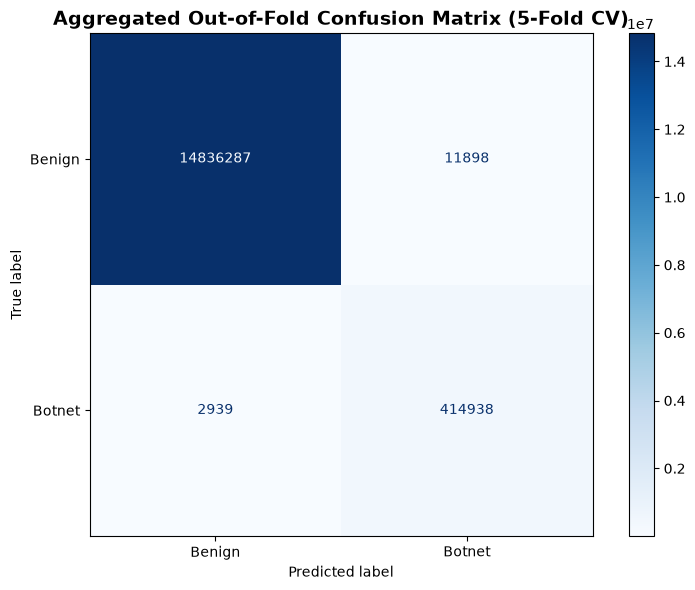

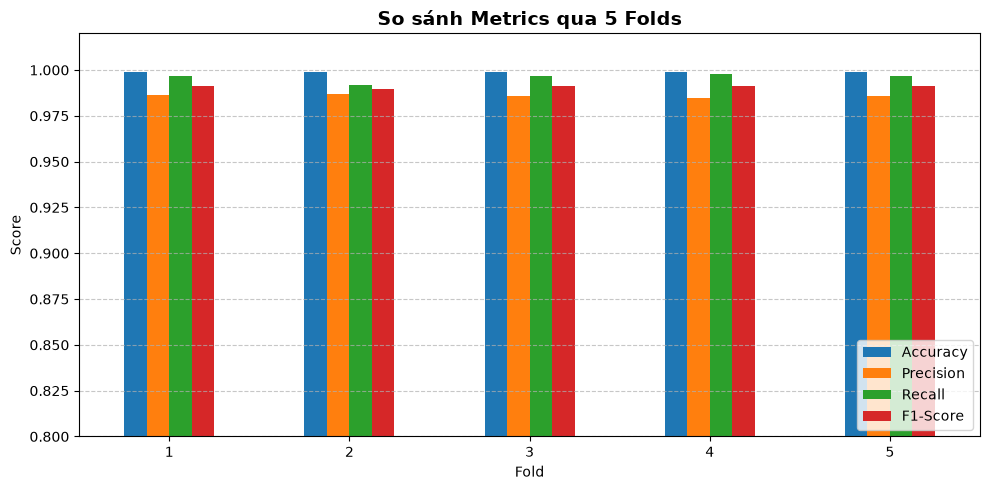

In [7]:
# =========================================================================
# 📈 BÁO CÁO TỔNG HỢP VÀ TRỰC QUAN HÓA KẾT QUẢ K-FOLD CROSS-VALIDATION
# =========================================================================

# 1. Bảng tổng hợp các Fold và tính Mean ± Std
df_summary = pd.DataFrame(fold_results).set_index('Fold')

mean_row = df_summary.mean()
std_row  = df_summary.std()

df_report = df_summary.copy()
df_report.loc['Mean'] = mean_row
df_report.loc['Std']  = std_row

print(f"\n{'='*75}")
print(f"🏆 BẢNG TỔNG HỢP KẾT QUẢ {K_FOLDS}-FOLD CROSS-VALIDATION:")
print(f"{'='*75}")
print(df_report.to_string(formatters={
    'Accuracy': '{:.4f}'.format,
    'Precision': '{:.4f}'.format,
    'Recall': '{:.4f}'.format,
    'F1-Score': '{:.4f}'.format,
    'Botnet_Recall': '{:.4f}'.format,
    'Botnet_F1': '{:.4f}'.format
}))
print(f"{'='*75}\n")

print(f"📌 KẾT LUẬN HIỆU NĂNG TỔNG THỂ:")
print(f"   Accuracy : {mean_row['Accuracy']:.4f} ± {std_row['Accuracy']:.4f}")
print(f"   Precision: {mean_row['Precision']:.4f} ± {std_row['Precision']:.4f}")
print(f"   Recall   : {mean_row['Recall']:.4f} ± {std_row['Recall']:.4f}")
print(f"   F1-Score : {mean_row['F1-Score']:.4f} ± {std_row['F1-Score']:.4f}")
print(f"   Botnet F1: {mean_row['Botnet_F1']:.4f} ± {std_row['Botnet_F1']:.4f}\n")

# 2. Confusion Matrix Tổng hợp (Cộng dồn toàn bộ các Fold)
total_cm = np.sum(fold_cms, axis=0)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=total_cm,
    display_labels=CLASS_NAMES
).plot(ax=ax, cmap='Blues', values_format='d', colorbar=True)
ax.set_title(f'Aggregated Out-of-Fold Confusion Matrix ({K_FOLDS}-Fold CV)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('kfold_aggregated_confusion_matrix.png', dpi=200)
plt.show()

# 3. Biểu đồ cột so sánh độ ổn định các metrics qua các fold
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
ax_bar = df_summary[metrics_to_plot].plot(kind='bar', figsize=(10, 5), rot=0, ylim=[0.8, 1.02])
plt.title(f'So sánh Metrics qua {K_FOLDS} Folds', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.xlabel('Fold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('kfold_metrics_comparison.png', dpi=200)
plt.show()